# Кандидатогенерация для категории «Услуги» Авито

**Задача.** Для каждого из 2 452 поисковых запросов отобрать из корпуса (189 212 объявлений) до 50 кандидатов так,
чтобы в них попало объявление, которое пользователь в итоге выбрал. Метрика — **Recall@50**.

**Решение в одном абзаце.** Сначала корпус сужается до «разрешённых» локаций. Их три вида: своя, те, куда
реально уходят пользователи из этой локации (по train), и соседние в радиусе 60 км. Затем несколько независимых
источников дают кандидатов: BM25 по заголовку и полному тексту, символьные n-граммы, расширение запроса через
похожие запросы из train, классификатор подкатегории и небольшой глобальный источник без фильтра по локации.
Получается пул ~400 объявлений на запрос с полнотой ~0.96. Из пула LightGBM LambdaRank по 30 признакам
выбирает 50.

**Запуск:** выполнить ячейки сверху вниз или `python run_pipeline.py --data_dir data`. Промежуточные результаты
кэшируются в `cache/`; описание модулей — в README.

In [1]:
import sys, json
sys.path.insert(0, 'src')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pipeline import Pipeline

DATA_DIR = 'data'      # папка с train.parquet, benchmark_items.parquet, benchmark_queries.parquet
CACHE_DIR = 'cache'
pd.set_option('display.max_colwidth', 80)
pl = Pipeline(DATA_DIR, CACHE_DIR, n_holdout=10_000, train_rows=0)   # train_rows=0 -> весь train

## 1. Подготовка данных

`prepare()` объединяет объявления корпуса и объявления из train (их тексты нужны для расширения запроса и
валидации). Затем лемматизирует заголовок, параметры и первые 120 слов описания и разбирает фильтры.
Train читается **кусками по ~20 тыс. строк**, и каждый кусок сразу сохраняется. Так пиковая память
не зависит от размера train, а после обрыва подготовка продолжается с первого необработанного куска.

In [2]:
pl.prep()
items, pairs, bq = pl.items, pl.pairs, pl.bq
items.head(3)

[    1.6s] [prep] объявлений 515895, пар train 497673, запросов бенчмарка 2452


,item_id,in_bench,item_title_raw,item_location_id,item_microcat_id,item_category_id,item_latitude,item_longitude,item_price,item_rating,item_rating_reviews_count,i_vid,i_tips,title_lem,params_lem,desc_lem,title_norm
0,111eb8b979577d79,True,Ремонт/выкуп компьют. и ноутбуков с выездом на дом,631060,2097573,114,44.228180,42.047194,500.0,5.0,57.0,Компьютерная помощь,Компьютеры,ремонт выкуп компить ноутбук выезд дом,вид услуга компьютерный помощь тип стоимость услуга начальный цена график ра...,выезд дом любой время вплоть 23 00 диагностика устройство чистка пыль замена...,ремонт выкуп компьют и ноутбуков с выездом на дом
1,75fc8e10f5a66fc4,True,Обучение ребенка чтению,631870,86453,114,58.627609,49.627392,900.0,5.0,7.0,"Обучение, курсы","Детское развитие, логопеды",обучение ребенок чтение,вид услуга обучение курс тип услуга детский развитие логопед тип стоимость у...,дорогой родитель маленький книголюб детский психолог нейропсихолог рада приг...,обучение ребенка чтению
2,3f6ae81704565b9c,True,Афрокудри 5+,628500,86467,114,56.990307,40.936892,1000.0,5.0,14.0,"Красота, здоровье",Услуги парикмахера,афрокудри,вид услуга красота здоровье тип услуга услуга парикмахер тип стоимость услуг...,внимание укладка афрокудри отличный вариант замена хим завивка если хотеться...,афрокудри 5


## 2. Что показал анализ данных
### 2.1 Локация — главный фильтр

In [3]:
p = pairs.merge(items[['item_id', 'item_location_id']], on='item_id')
same = (p.search_location_id == p.item_location_id)
print(f'локация объявления == локация поиска: {same.mean():.1%}')
mis = p[~same]
print(f'среди несовпадений локация поиска не встречается у объявлений (регион / вся страна): '
      f'{(~mis.search_location_id.isin(set(items.item_location_id))).mean():.1%}')
for loc in mis.search_location_id.value_counts().index[:3]:
    x = p[p.search_location_id == loc].item_location_id.value_counts(normalize=True)
    print(f'  поиск в {loc}: выборы в {len(x)} локациях, топ-3 доли {x.head(3).round(3).to_dict()}')

локация объявления == локация поиска: 83.1%
среди несовпадений локация поиска не встречается у объявлений (регион / вся страна): 63.9%
  поиск в 107620: выборы в 233 локациях, топ-3 доли {637640: 0.612, 638790: 0.028, 637770: 0.024}
  поиск в 621540: выборы в 590 локациях, топ-3 доли {637640: 0.273, 653240: 0.107, 633540: 0.032}
  поиск в 107621: выборы в 138 локациях, топ-3 доли {653240: 0.795, 636840: 0.038, 636736: 0.018}


**Вывод.** Фильтровать нужно не только по своей локации, но и по выученному распределению
P(локация объявления | локация поиска), плюс учитывать соседние города. Без этого теряется ~8% релевантных
объявлений.

### 2.2 Запомнить объявления из train не получится

In [4]:
bench = items[items.in_bench]
print(f'объявлений корпуса, встречавшихся в train: {bench.item_id.isin(set(pairs.item_id)).mean():.1%}')
print(f'текстов запросов бенчмарка, встречавшихся в train: {bq.search_query.isin(set(pairs.search_query)).mean():.1%}')

объявлений корпуса, встречавшихся в train: 9.6%


текстов запросов бенчмарка, встречавшихся в train: 37.0%


**Вывод.** Нужно сопоставлять смысл текста. Из train при этом можно выучить обобщаемые связи: запрос →
подкатегория, запрос → слова в заголовках выбранных объявлений, локация → локации.

### 2.3 Бенчмарк не похож на случайную выборку из train

In [5]:
g = pairs.drop_duplicates(['search_query', 'search_location_id', 'search_infm_params_text'])
u = g.drop_duplicates('search_query')
pd.DataFrame({
    'train (все группы)': [g.search_query.str.split().str.len().mean(), (g.search_infm_params_text != '').mean()],
    'train (уникальные тексты)': [u.search_query.str.split().str.len().mean(), (u.search_infm_params_text != '').mean()],
    'бенчмарк': [bq.search_query.str.split().str.len().mean(), (bq.search_infm_params_text != '').mean()],
}, index=['слов в запросе', 'доля с фильтрами']).round(2)

,train (все группы),train (уникальные тексты),бенчмарк
слов в запросе,2.45,3.10,3.20
доля с фильтрами,0.65,0.53,0.37


**Вывод.** Бенчмарк ближе к выборке уникальных текстов (длинный хвост), и валидацию нужно строить так же.

### 2.4 Фильтры из параметров запроса надёжны

In [6]:
p = pairs.merge(items[['item_id', 'i_vid', 'i_tips', 'item_rating']], on='item_id')
v, t, r = p[p.q_vid != ''], p[p.q_tips != ''], p[p.q_rating4 == 1]
print(f'«Вид услуги» совпадает: {(v.q_vid == v.i_vid).mean():.1%} (n={len(v)})')
tip_ok = [bool(set(a.split("|")) & set(b.split("|")) - {""}) for a, b in zip(t.q_tips, t.i_tips)]
print(f'«Тип услуги» из фильтра есть у объявления: {np.mean(tip_ok):.1%} (n={len(t)})')
print(f'«Рейтинг 4+» соблюдён: {(r.item_rating.fillna(0) >= 4).mean():.1%} (n={len(r)})')

«Вид услуги» совпадает: 98.4% (n=320265)


«Тип услуги» из фильтра есть у объявления: 92.0% (n=175196)
«Рейтинг 4+» соблюдён: 99.1% (n=856)


## 3. Валидация, имитирующая бенчмарк (`src/split.py`)

1. Отложенные запросы берутся **равномерно по уникальным текстам**: 10 000 текстов, по одной группе
   (текст, локация, фильтры) на текст.
2. Для 73% из них из обучения удаляются все строки с этим текстом (новый запрос), для 27% — только сама группа.
   Это доля знакомых текстов в бенчмарке.
3. Корпус валидации = корпус бенчмарка + релевантные объявления отложенных запросов.
4. Отложенные запросы делятся на обучение ранкера (2/3) и валидацию (1/3). Ранняя остановка делается на части
   обучающих запросов, валидация в обучении не участвует.

Все статистики (классификатор, переходы локаций, расширение запроса) учатся только на оставшемся train,
поэтому утечки нет.

## 4. Кандидатогенерация (`src/retriever.py`)

| Источник | Что ловит | Топ-N |
|---|---|---|
| BM25 по заголовку | точные совпадения слов | 150 |
| BM25 по заголовку ×2 + параметрам + описанию | слова в описании услуги | 150 |
| TF-IDF по символьным 3–4-граммам | опечатки, словоформы | 100 |
| расширение запроса через похожие запросы train | синонимы, жаргон | 150 |
| P(подкатегория \| запрос), SGD-логрег | «наращивание ногтей» → маникюр | 100 |
| «память» по похожим прошлым запросам | популярные объявления | 30 |
| глобально (весь корпус): BM25 + расширение | соседние города, «вся Россия» | 60 + 40 |

In [7]:
pl.val_candidates()
pl.cand.head()

[   23.4s] [val_cands] кандидатов 4095317, в среднем 410 на запрос


,title,full,char,exp,mem,cat,mc_prob,mc_rank,qi,item_idx,...,log_reviews,has_price,item_pop,mc_pop,q_len,q_has_params,cat_ok,item_id,label,part
0,0.0,0.0,0.000000,5.252033,0.0,0.153026,0.144741,1,0,390,...,2.944439,1,0.0,8.023552,2,0,1,980bf695a9c63fc5,0,rank_train
1,0.0,0.0,0.046195,0.674381,0.0,0.001628,0.001514,13,0,3355,...,1.386294,1,0.0,9.819725,2,0,1,3d8a4a7a20c4b4f3,0,rank_train
2,0.0,0.0,0.063064,0.000000,0.0,0.000431,0.000407,32,0,3394,...,3.931826,1,0.0,8.405144,2,0,1,2e419eaa5d92ec5d,0,rank_train
3,0.0,0.0,0.000000,4.526910,0.0,0.153026,0.144741,1,0,4596,...,1.791759,1,0.0,8.023552,2,0,1,3a5b5dbc86dbad65,0,rank_train
4,0.0,0.0,0.030729,0.000000,0.0,0.023304,0.022369,4,0,4656,...,2.890372,1,0.0,6.472346,2,0,1,753d81a0bfb8100e,0,rank_train


## 5. Ранкер и результаты

LightGBM LambdaRank оптимизирует порядок внутри каждого запроса (`group`). `lambdarank_truncation_level=60`
фокусирует обучение на границе топ-50. У модели 30 признаков: скоры источников (сырые и нормированные на
максимум в запросе), подкатегория, локация, расстояние, совпадение фильтров, рейтинг, популярность.

In [8]:
pl.val_ranker()
rep = pl.report
pd.Series({'BM25 по всему корпусу': rep['bm25_whole_corpus'],
           'BM25 + фильтр по локации': rep['bm25_location_filter'],
           'Полнота пула (верхняя граница)': rep['candidate_pool_upper_bound'],
           'Итог: пул + LightGBM': rep['final_recall@50']}).round(4).to_frame('Recall@50')

[   23.4s] [val_ranker] Recall@50: {"train_pairs_used": 497673, "n_val_queries": 3355, "val_seen_share": 0.3699, "bm25_whole_corpus": 0.4062, "bm25_location_filter": 0.7848, "candidate_pool_upper_bound": 0.9546, "final_recall@50": 0.9075, "ranker_rounds": 180}


,Recall@50
BM25 по всему корпусу,0.4062
BM25 + фильтр по локации,0.7848
Полнота пула (верхняя граница),0.9546
Итог: пул + LightGBM,0.9075


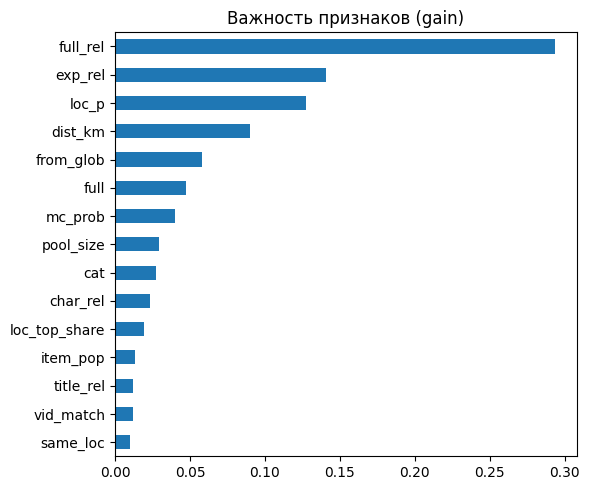

In [9]:
imp = pd.Series(rep['feature_importance']).head(15)
imp[::-1].plot.barh(figsize=(6, 5), title='Важность признаков (gain)'); plt.tight_layout()

## 6. Разбор ошибок на валидации

In [10]:
va = pd.read_parquet(pl.f['val_scored'])
hq = pl.hq
titles = items.set_index('item_id').item_title_raw
va['rank'] = va.groupby('qi').score.rank(ascending=False, method='first')
rows = [(i, it) for i in hq.index[hq.part == 'val'] for it in hq.relevant[i]]
d = pd.DataFrame(rows, columns=['qi', 'item_id']).merge(va[['qi', 'item_id', 'rank']], how='left')
d['status'] = np.select([d['rank'].isna(), d['rank'] <= 50], ['нет в пуле', 'в топ-50'], 'в пуле, ниже 50')
d.status.value_counts(normalize=True).round(3)

status
в топ-50           0.906
в пуле, ниже 50    0.049
нет в пуле         0.045
Name: proportion, dtype: float64

In [11]:
def show(status, n=8, seed=0):
    out = []
    for _, r in d[d.status == status].sample(n, random_state=seed).iterrows():
        top1 = va[(va.qi == r.qi) & (va['rank'] == 1)].item_id
        out.append({'запрос': hq.search_query[r.qi], 'выбранное': titles[r.item_id][:55],
                    'ранг': r['rank'], 'наш топ-1': titles[top1.iloc[0]][:45] if len(top1) else None})
    return pd.DataFrame(out)
show('в пуле, ниже 50')

,запрос,выбранное,ранг,наш топ-1
0,услуги кузнеца,Художественная ковка,90.0,Художественная ковка кузнец ограждения метал
1,услуги байера китай,Посредник из Китая/ Заказы из Китая,110.0,"Байер. США, Европа, Япония, Китай"
2,сканирование книг,Напишу книгу из переписки или Telegram-канала,71.0,"Сканирование, распознавание, создание эл. кни"
3,программирование arduino,"Программирование Arduino, stm32, ESP",71.0,Программирование Python для детей онлайн
4,аренда портера без водителя,Аренда Hyundai Porter без водителя,127.0,"Аренда Hyundai Портер 1, есть рефрижераторы"
5,скупка техники sony hdr-fx7e,Выкуп техники в касание,100.0,"Скупка техники, вещей,вывоз хлама орг техники"
6,водительские права в рассрочку,Обучение в автошколе,105.0,Автоюрист по лишению водительских прав
7,покраска на высоте,Промышленный альпинист высотные работы,57.0,"Покраска автомобиля, кузовной ремонт"


Обычно здесь общий запрос («няня», «покраска волос»), и подходящих объявлений в городе больше 50. Наш топ-1 тоже релевантен: это неоднозначность, а не ошибка модели.

In [12]:
show('нет в пуле')

,запрос,выбранное,ранг,наш топ-1
0,подключить домофон,Штукатурные работы,NaN,"Установка и ремонт домофонов,видеодомофон"
1,volkswagen caddy аренда,Аренда автомобиля Citroen Berlingo,NaN,Аренда авто с выкупом Volkswagen Polo рассроч
2,изготовление ограждений из дерева,Услуги столяра и плотника,NaN,"Мебель на заказ, столярная мастерская"
3,115-фз,Бухгалтерские услуги для ИП и ООО / Бухгалтер УСН,NaN,Разблокировка счета по 115 фз разблокировка 1
4,грузчики гальяново,Грузчики на час разнорабочие Курск/Курчатов,NaN,Грузчики
5,холодный плазмолифтинг,Прокол ушей пистолетом,NaN,Скульптурный массаж лица. Массаж тела
6,диагностика инфинити,Диагност - Электрик Nissan Infiniti,NaN,Ремонт АКПП infiniti GF018
7,айкидо,"Индивидуальные тренировки по самообороне, цао",NaN,Тренер по Айкидо


Промахи мимо пула бывают трёх видов: у выбранного объявления общий заголовок без слов запроса («Мастер на час»), транслитерация («джисиби» → «JCB»), шум в разметке.

In [13]:
vq = hq[hq.part == 'val']
hit = d.assign(h=d.status == 'в топ-50').groupby('qi').h.mean()
vq = vq.assign(recall=hit.reindex(vq.index).values, words=vq.search_query.str.split().str.len().clip(upper=5))
vq.groupby('words').recall.agg(['mean', 'size']).round(3)

,mean,size
words,,
1,0.815,146
2,0.898,1032
3,0.921,1119
4,0.927,671
5,0.893,387


## 7. Ответ для бенчмарка

Ранкер переобучается на всех отложенных запросах, а для запросов бенчмарка статистики (классификатор,
переходы локаций, расширение) учатся на **всём** train. Корпус — только `benchmark_items`.
`check_answer` проверяет все требования к файлу из условия.

In [14]:
pl.final_ranker()
del pl.cand
pl.bench_candidates()
ans = pl.answer('answer.csv')
print(ans.shape, ans.answer.str.split().str.len().agg(['min', 'max']).to_dict())
ans.head()

[   34.3s] [bench_cands] 957260 строк


[   42.1s] [answer] готово: answer.csv


(2452, 2) {'min': 50, 'max': 50}


,query_id,answer
0,70DfDUpwjxB4lzFd,6047e1566a959d3a fa4ba2c2cf71b0b1 603623b4bd9e8f6c 94c5ec723ea5418f 4494aa11...
1,JTrdTaZJvSiLPkXj,422d3ffdd5bbf626 cbeccbecb1fb8d86 1344796085e92421 1c6d2079e07f4497 367af128...
2,LZCZNoVG4AFUkVRJ,dab52187b4500d9b c5d21c0e8c1cdb2d 3f89b8062dc85f1c d8fce513e4f000a7 168a9207...
3,660ac9QVtXkRxZC3,af91ec4a29b66636 4c15e7abba063ac5 3cce43c811459438 bd2cb4500fad728e 5b8181f0...
4,YgHcM9MVbxKnxD1e,1a62634394544781 615c73ea4c3bfd15 4ef5ba70fa9baaef 442b0ab445da8fa8 9c41fe78...


In [15]:
# глазами: что мы нашли для нескольких запросов бенчмарка
for i in [0, 5, 500, 1500]:
    ids = ans.answer[i].split()[:3]
    print(bq.search_query[i], '->', [titles[x][:40] for x in ids])

перевозки владикавказ тбилиси -> ['Такси Бизнес.Трансфер Межгород.Владикавк', 'Трансфер-такси-Владикавказ-Гудаури-Тбили', 'Владикавказ Тбилиси трансфер такси в Гру']
боевое самбо -> ['Боевое самбо и самбо', 'Секция Боевого Самбо', 'Спортивное и боевое самбо']
баня -> ['Аренда бани/Баня бочка/Баня на колесах', 'Аренда бани бочки на колесах', 'Баня на колесах аренда']
вакансия репетитор онлайн математика информатика -> ['Онлайн Репетитор - Математика \\ Информат', 'Репетитор по математике и информатике ОГ', 'Репетитор математика, информатика 5-11 к']
